In [1]:
pip install psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# AI Workforce Intervention
## Predictive Analysis using Machine Learning

## In this notebook, we move beyond descriptive analysis and build a predictive model to identify
## employees who are likely to be at high layoff risk based on workforce characteristics. 

In [2]:
# 1. Import Required Libraries

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# PostgreSQL connection
from sqlalchemy import create_engine

# Machine Learning
from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
## 1.1 Project Configuration

## This section stores all database connection settings in one place. 
## Keeping configuration separate from the main code improves readability 
## and makes the project easier to maintain.

# PostgreSQL Database Configuration

DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "ai_workforce_intervention"

DB_USER = "postgres"
DB_PASSWORD = "312003"

# Database Connection URL

DATABASE_CONNECTION_STRING = (
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

In [4]:
## 2. Connect to PostgreSQL Database

## Rather than loading a CSV file, this project connects directly to the 
## PostgreSQL database created during the SQL phase. This ensures the machine learning model 
## uses the cleaned and structured reporting dataset.

# Create the SQLAlchemy Engine

engine = create_engine(DATABASE_CONNECTION_STRING)

print("Database connection created successfully!")

Database connection created successfully!


In [5]:
# 3. Load Workforce Dataset (Reporting View)
## The Reporting View combines employee profile, AI adoption metrics, 
## and job risk into a single analytical dataset. This eliminates the need 
## to recreate SQL joins inside Python and provides a clean dataset for machine learning.

query = """
SELECT * FROM AI_Workforce.Reporting_View; 
"""

workforce_df = pd.read_sql(query, engine)

print("Reporting View loaded successfully!")

Reporting View loaded successfully!


In [6]:
## Data Validation

workforce_df.head()

,emp_id,age,edu_level,year_of_exp,industry_name,role_name,company_size_name,job_level_name,routine_task_percentage,creativity_requirement,human_interaction_level,ai_adoption_level,no_of_ai_tools_used,ai_usage_hours_per_week,task_automated_group,ai_training_hours,layoff_risk
0,1,59,Master's,6,Finance,Accountant,Medium,Entry,84.0,Low,High,Medium,5.0,7.0,40.0,26.0,High
1,2,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30.0,High,Medium,Low,2.0,2.0,14.0,9.0,High
2,3,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12.0,High,High,Low,0.0,1.0,6.0,3.0,Low
3,4,27,Bachelor's,6,Finance,Auditor,Large,Entry,90.0,Low,Low,Medium,3.0,10.0,67.0,26.0,High
4,5,49,High School,12,Finance,Auditor,Small,Entry,49.0,Medium,High,Medium,5.0,13.0,26.0,19.0,Medium


In [7]:
workforce_df.shape

(20001, 17)

In [8]:
workforce_df.columns

Index(['emp_id', 'age', 'edu_level', 'year_of_exp', 'industry_name',
       'role_name', 'company_size_name', 'job_level_name',
       'routine_task_percentage', 'creativity_requirement',
       'human_interaction_level', 'ai_adoption_level', 'no_of_ai_tools_used',
       'ai_usage_hours_per_week', 'task_automated_group', 'ai_training_hours',
       'layoff_risk'],
      dtype='str')

In [9]:
workforce_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20001 entries, 0 to 20000
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   emp_id                   20001 non-null  int64  
 1   age                      20001 non-null  int64  
 2   edu_level                20001 non-null  str    
 3   year_of_exp              20001 non-null  int64  
 4   industry_name            20001 non-null  str    
 5   role_name                20001 non-null  str    
 6   company_size_name        20001 non-null  str    
 7   job_level_name           20001 non-null  str    
 8   routine_task_percentage  20000 non-null  float64
 9   creativity_requirement   20000 non-null  str    
 10  human_interaction_level  20000 non-null  str    
 11  ai_adoption_level        20000 non-null  str    
 12  no_of_ai_tools_used      20000 non-null  float64
 13  ai_usage_hours_per_week  20000 non-null  float64
 14  task_automated_group     20000 no

In [10]:
## 4. Data Quality Assessment

### Before building a machine learning model, the dataset is 
## inspected for missing values and potential data quality issues. 
## This ensures that the model is trained on complete and reliable data.

workforce_df.isnull().sum()

emp_id                     0
age                        0
edu_level                  0
year_of_exp                0
industry_name              0
role_name                  0
company_size_name          0
job_level_name             0
routine_task_percentage    1
creativity_requirement     1
human_interaction_level    1
ai_adoption_level          1
no_of_ai_tools_used        1
ai_usage_hours_per_week    1
task_automated_group       1
ai_training_hours          1
layoff_risk                1
dtype: int64

In [11]:
# Which row is null?
workforce_df[workforce_df.isnull().any(axis=1)]

,emp_id,age,edu_level,year_of_exp,industry_name,role_name,company_size_name,job_level_name,routine_task_percentage,creativity_requirement,human_interaction_level,ai_adoption_level,no_of_ai_tools_used,ai_usage_hours_per_week,task_automated_group,ai_training_hours,layoff_risk
319,20001,28,Bachelor,4,Retail,Academic Coordinator,Small,Senior,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
### Removing Test Record

## During SQL development, a test employee record was inserted to demonstrate Trigger functionality. 
## Since this record contains incomplete values and does not represent a real employee, 
## it is removed before model training.

# Remove rows containing missing values
workforce_df = workforce_df.dropna()

print("Database cleaned successfully!")
print(f"Remaining records: {len(workforce_df)}")

Database cleaned successfully!
Remaining records: 20000


In [13]:
workforce_df.info()

<class 'pandas.DataFrame'>
Index: 20000 entries, 0 to 20000
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   emp_id                   20000 non-null  int64  
 1   age                      20000 non-null  int64  
 2   edu_level                20000 non-null  str    
 3   year_of_exp              20000 non-null  int64  
 4   industry_name            20000 non-null  str    
 5   role_name                20000 non-null  str    
 6   company_size_name        20000 non-null  str    
 7   job_level_name           20000 non-null  str    
 8   routine_task_percentage  20000 non-null  float64
 9   creativity_requirement   20000 non-null  str    
 10  human_interaction_level  20000 non-null  str    
 11  ai_adoption_level        20000 non-null  str    
 12  no_of_ai_tools_used      20000 non-null  float64
 13  ai_usage_hours_per_week  20000 non-null  float64
 14  task_automated_group     20000 non-nul

In [14]:
## 5. Prepare Features and Target Variable

## Machine learning models learn patterns from input variables (features) to 
## predict an output (target). In this project, employee characteristics and 
## AI adoption metrics are used as features, while Layoff Risk is the target variable to be predicted.
 
# Target Variable
target = workforce_df["layoff_risk"]

# Feature Variable
features = workforce_df.drop(columns=["layoff_risk", "emp_id"])

In [15]:
print(target.shape)
print(features.shape)

(20000,)
(20000, 15)


In [16]:
features.head()

,age,edu_level,year_of_exp,industry_name,role_name,company_size_name,job_level_name,routine_task_percentage,creativity_requirement,human_interaction_level,ai_adoption_level,no_of_ai_tools_used,ai_usage_hours_per_week,task_automated_group,ai_training_hours
0,59,Master's,6,Finance,Accountant,Medium,Entry,84.0,Low,High,Medium,5.0,7.0,40.0,26.0
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30.0,High,Medium,Low,2.0,2.0,14.0,9.0
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12.0,High,High,Low,0.0,1.0,6.0,3.0
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90.0,Low,Low,Medium,3.0,10.0,67.0,26.0
4,49,High School,12,Finance,Auditor,Small,Entry,49.0,Medium,High,Medium,5.0,13.0,26.0,19.0


In [17]:
target.head()

0      High
1      High
2       Low
3      High
4    Medium
Name: layoff_risk, dtype: str

In [18]:
## 6. Encode Categorical Variables

## Machine learning algorithms require numerical inputs. 
## Therefore, all categorical variables are converted into numerical values 
## using Label Encoding before model training.

categorical_columns = features.select_dtypes(include = "object").columns
print(categorical_columns)

Index(['edu_level', 'industry_name', 'role_name', 'company_size_name',
       'job_level_name', 'creativity_requirement', 'human_interaction_level',
       'ai_adoption_level'],
      dtype='str')


C:\Users\Siddharth Rana\AppData\Local\Temp\ipykernel_20408\3014824252.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = features.select_dtypes(include = "object").columns


In [ ]:
# # Create Label Encoder

# encoder = LabelEncoder()

# # Encode Categorical Variable

# for column in categorical_columns: 
#     features[column] = encoder.fit_transform(features[column])

In [19]:
features.head(7)

,age,edu_level,year_of_exp,industry_name,role_name,company_size_name,job_level_name,routine_task_percentage,creativity_requirement,human_interaction_level,ai_adoption_level,no_of_ai_tools_used,ai_usage_hours_per_week,task_automated_group,ai_training_hours
0,59,Master's,6,Finance,Accountant,Medium,Entry,84.0,Low,High,Medium,5.0,7.0,40.0,26.0
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30.0,High,Medium,Low,2.0,2.0,14.0,9.0
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12.0,High,High,Low,0.0,1.0,6.0,3.0
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90.0,Low,Low,Medium,3.0,10.0,67.0,26.0
4,49,High School,12,Finance,Auditor,Small,Entry,49.0,Medium,High,Medium,5.0,13.0,26.0,19.0
5,45,PhD,9,Telecom,Network Engineer,Large,Entry,72.0,Low,Medium,Medium,4.0,5.0,69.0,9.0
6,48,Bachelor's,10,IT,Software Engineer,Small,Entry,46.0,Medium,Medium,Medium,2.0,7.0,45.0,9.0


In [ ]:
# Encode Target Variable

# target = encoder.fit_transform(target)
# target[:10]


In [ ]:
##### !!!! MAJOR ISSUE -- PROBLEM !!!!
#### Encoder assings numbers alphabetically, so it categorises low,med,high, the wrong way. 
### So, we take a step back, and re-write the code. 

In [20]:
workforce_df["edu_level"].unique()

<ArrowStringArray>
['Master's', 'Bachelor's', 'High School', 'PhD']
Length: 4, dtype: str

In [21]:
workforce_df["company_size_name"].unique()

<ArrowStringArray>
['Medium', 'Small', 'Large']
Length: 3, dtype: str

In [22]:
workforce_df["job_level_name"].unique()

<ArrowStringArray>
['Entry', 'Senior', 'Mid']
Length: 3, dtype: str

In [23]:
## 7. Feature Engineering

## Not all categorical variables should be encoded the same way.
## Ordinal variables (those with a natural order) are manually mapped to preserve their ranking.
## Nominal variables (those without any order) are transformed using One-Hot Encoding to 
## avoid introducing artificial relationships between categories.

# Manual Encoding for Ordinal Variables

education_mapping = {
    "High School": 0,
    "Bachelor's": 1,
    "Master's": 2,
    "PhD": 3
}

company_mapping = {
    "Small": 0,
    "Medium": 1,
    "Large": 2
}

job_level_mapping = {
    "Entry": 0,
    "Mid": 1,
    "Senior": 2
}

level_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}



In [24]:
# Apply mappings

features["edu_level"] = features["edu_level"].map(education_mapping)

features["company_size_name"] = features["company_size_name"].map(company_mapping)

features["job_level_name"] = features["job_level_name"].map(job_level_mapping)

features["ai_adoption_level"] = features["ai_adoption_level"].map(level_mapping)

features["creativity_requirement"] = features["creativity_requirement"].map(level_mapping)

features["human_interaction_level"] = features["human_interaction_level"].map(level_mapping)

# Encode target

target = workforce_df["layoff_risk"].map(level_mapping)

In [25]:
# features.head()
target.head()

0    2
1    2
2    0
3    2
4    1
Name: layoff_risk, dtype: int64

In [26]:
# ==========================================
# One-Hot Encode Nominal Variables
# ==========================================

features = pd.get_dummies(
    features,
    columns=[
        "industry_name",
        "role_name"
    ],
    drop_first=True
)

In [22]:
features.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 0 to 20000
Data columns (total 43 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              20000 non-null  int64  
 1   edu_level                        20000 non-null  int64  
 2   year_of_exp                      20000 non-null  int64  
 3   company_size_name                20000 non-null  int64  
 4   job_level_name                   20000 non-null  int64  
 5   routine_task_percentage          20000 non-null  float64
 6   creativity_requirement           20000 non-null  int64  
 7   human_interaction_level          20000 non-null  int64  
 8   ai_adoption_level                20000 non-null  int64  
 9   no_of_ai_tools_used              20000 non-null  float64
 10  ai_usage_hours_per_week          20000 non-null  float64
 11  task_automated_group             20000 non-null  float64
 12  ai_training_hours      

In [ ]:
## 8. Split the Dataset

## To evaluate the model fairly, the dataset is divided into two parts:

## - **Training Set** – Used to teach the model patterns from historical employee data.
## - **Testing Set** – Used to evaluate how well the model predicts employees it has never seen before.

## This helps measure how well the model generalizes to new data instead of simply memorizing the training records.

In [27]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    features, 
    target, 
    test_size = 0.20, 
    random_state = 42 # randomize emp for training the machine every time
)


#### Instead of training the dataset on entire 20,000 data, we train on 16,000 and test on the rest 4000!

In [28]:
print("Training Features: ", x_train.shape)
print("Testing Features: ", x_test.shape)

print("Training Features: ", y_train.shape)
print("Testing Features: ", y_test.shape)

Training Features:  (16000, 43)
Testing Features:  (4000, 43)
Training Features:  (16000,)
Testing Features:  (4000,)


In [29]:
features.columns

Index(['age', 'edu_level', 'year_of_exp', 'company_size_name',
       'job_level_name', 'routine_task_percentage', 'creativity_requirement',
       'human_interaction_level', 'ai_adoption_level', 'no_of_ai_tools_used',
       'ai_usage_hours_per_week', 'task_automated_group', 'ai_training_hours',
       'industry_name_Finance', 'industry_name_Healthcare', 'industry_name_IT',
       'industry_name_Logistics', 'industry_name_Manufacturing',
       'industry_name_Retail', 'industry_name_Telecom', 'role_name_Accountant',
       'role_name_Auditor', 'role_name_Data Analyst', 'role_name_Dispatcher',
       'role_name_Financial Analyst', 'role_name_Health Analyst',
       'role_name_Inventory Analyst', 'role_name_ML Engineer',
       'role_name_Medical Assistant', 'role_name_Network Engineer',
       'role_name_Nurse', 'role_name_Operations Analyst', 'role_name_Operator',
       'role_name_Production Supervisor', 'role_name_Quality Engineer',
       'role_name_Research Assistant', 'role_name_

In [30]:
features.shape

(20000, 43)

In [31]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
### Randome Forest -->  It's a collection of trees
### Instead of relying on one tree, it collects every tree, and then based on higest vote, answers and predicts.
## One tree can make mistakes. 100 trees usually make fewer mistakes. 

In [32]:
# 9. Train Machine Learning Model

# Create Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators = 100,  # build 100 decision trees.
    random_state = 42 # random state
)

In [33]:
# Training the model

rf_model.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
## 10. Generate Predictions

## After learning from the training dataset, the model is tested on employees 
## it has never seen before. This evaluates how well the model generalizes to new data 
## rather than simply memorizing historical records.

In [35]:
predictions = rf_model.predict(x_test)

In [36]:
# Predict High-Risk Employees; 0: Low, 1: Medium, 2: High
print(predictions[:10])

[0 0 1 0 0 2 2 0 2 0]


In [38]:
# Import Evaluation Metrics

from sklearn.metrics import(
    accuracy_score, 
    confusion_matrix,
    classification_report
)

In [39]:
## Calculate Accuracy

accuracy = accuracy_score(y_test, predictions)

print(f"Model Accuracy: {accuracy: .2%}")

Model Accuracy:  88.50%


In [40]:
# Generating Confusion Matrix

cm = confusion_matrix(y_test, predictions)

print(cm)

# ##                  Predicted

#                Low   Med   High
# Actual Low    1189   113     0
# Actual Med      97  1104   130
# Actual High      0   136  1231

[[1207   95    0]
 [ 100 1100  131]
 [   0  134 1233]]


In [41]:
import matplotlib.pyplot as plt

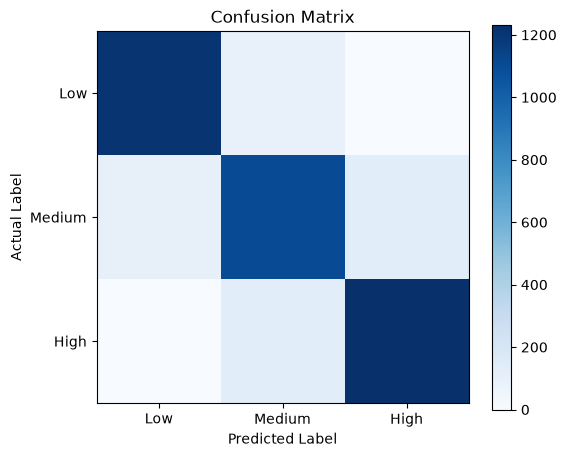

In [42]:
## Visualizing Confusion Matrix

plt.figure(figsize=(6,5))

plt.imshow(cm, interpolation = "nearest", cmap = "Blues")

plt.title("Confusion Matrix")

plt.colorbar()

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.xticks([0,1,2], ["Low", "Medium", "High"])

plt.yticks([0,1,2], ["Low", "Medium", "High"])



plt.show()

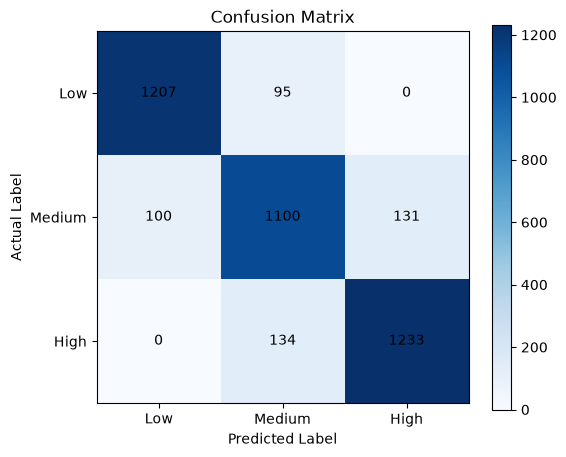

In [43]:
## Visualizing Confusion Matrix

plt.figure(figsize=(6,5))

plt.imshow(cm, interpolation = "nearest", cmap = "Blues")

plt.title("Confusion Matrix")

# plt.colorbar()

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.xticks([0,1,2], ["Low", "Medium", "High"])

plt.yticks([0,1,2], ["Low", "Medium", "High"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i, 
            cm[i,j], 
            ha = "center", 
            va = "center", 
            color = "black"
        )

plt.colorbar()

plt.show()

In [44]:
## 12. Classification Report

## Accuracy tells us how many predictions were correct overall. 
## However, it does not explain how well the model performs for each individual class (Low, Medium, and High). 
## The classification report provides a detailed evaluation using Precision, Recall, and F1-Score.

print(
    classification_report(
        y_test,
        predictions,
        target_names = ["Low", "Medium", "High"]
    )
)


### Precision: Prediction vs Real --> How well is the prediction? 
### Recall: How many did the model catch? If it says, 91% low, that means, it found 91% low
### F1-Score: Precision + Recall (High P + High R = High F1)
### Support: How many belonged actually to that class? 

              precision    recall  f1-score   support

         Low       0.92      0.93      0.93      1302
      Medium       0.83      0.83      0.83      1331
        High       0.90      0.90      0.90      1367

    accuracy                           0.89      4000
   macro avg       0.89      0.89      0.89      4000
weighted avg       0.88      0.89      0.88      4000



In [ ]:
## 13. Feature Importance

## One advantage of Random Forest is that it can estimate 
## which employee characteristics contribute the most to predicting layoff risk.

## This helps explain **why** the model makes its predictions, 
## making the results more interpretable for decision-makers.

In [45]:
# Extract Feature Importance

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame(
    {"Features": x_train.columns, 
    "Importance": importance
    }
)

feature_importance = feature_importance.sort_values(
    by = "Importance", 
    ascending = False
)

feature_importance.head(10)

,Features,Importance
5,routine_task_percentage,0.178126
11,task_automated_group,0.151144
4,job_level_name,0.091593
6,creativity_requirement,0.089703
10,ai_usage_hours_per_week,0.056488
12,ai_training_hours,0.053772
2,year_of_exp,0.049608
1,edu_level,0.042151
0,age,0.041533
9,no_of_ai_tools_used,0.038304


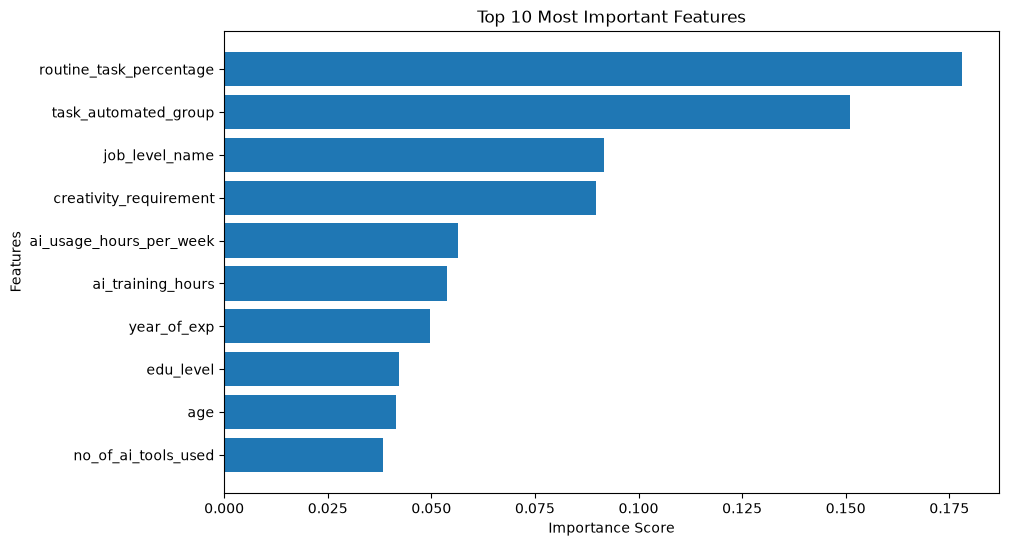

In [46]:
top_features = feature_importance.head(10)

plt.figure(figsize= (10,6))

plt.barh(
    top_features["Features"],
    top_features["Importance"]
)

plt.title("Top 10 Most Important Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
### Assume a new employee joins, can our model predict the layoff risk based on the factors?? 

In [ ]:
## 14. Predicting Risk for a New Employee

## The trained model can now be used to estimate the layoff risk of a completely 
## new employee based on their characteristics.

In [ ]:
# ==========================================
# Create a New Employee
# ==========================================

new_employee = pd.DataFrame({

    "age": [27],
    "edu_level": [2],                 # Bachelor's
    "year_of_exp": [3],
    "company_size_name": [2],         # Medium
    "job_level_name": [1],            # Entry
    "routine_task_percentage": [92],
    "creativity_requirement": [1],    # Low
    "human_interaction_level": [1],   # Low
    "ai_adoption_level": [3],         # High
    "no_of_ai_tools_used": [8],
    "ai_usage_hours_per_week": [24],
    "task_automated_group": [88],
    "ai_training_hours": [5],

    "industry_name_Finance": [1],
    "industry_name_Healthcare": [0],
    "industry_name_IT": [0],
    "industry_name_Logistics": [0],
    "industry_name_Manufacturing": [0],
    "industry_name_Retail": [0],
    "industry_name_Telecom": [0],

    "role_name_Accountant": [1],
    "role_name_Auditor": [0],
    "role_name_Data Analyst": [0],
    "role_name_Dispatcher": [0],
    "role_name_Financial Analyst": [0],
    "role_name_Health Analyst": [0],
    "role_name_Inventory Analyst": [0],
    "role_name_ML Engineer": [0],
    "role_name_Medical Assistant": [0],
    "role_name_Network Engineer": [0],
    "role_name_Nurse": [0],
    "role_name_Operations Analyst": [0],
    "role_name_Operator": [0],
    "role_name_Production Supervisor": [0],
    "role_name_Quality Engineer": [0],
    "role_name_Research Assistant": [0],
    "role_name_Sales Associate": [0],
    "role_name_Software Engineer": [0],
    "role_name_Store Manager": [0],
    "role_name_Supply Chain Analyst": [0],
    "role_name_Support Specialist": [0],
    "role_name_Teacher": [0],
    "role_name_Warehouse Manager": [0]

})

In [ ]:
new_employee.shape

In [ ]:
## Predict the New Employee

prediction = rf_model.predict(new_employee)

prediction

### High Prediction?? 

In [ ]:
# ==========================================
# Convert Prediction to Label
# ==========================================

risk_labels = {
    0: "Low",
    1: "Medium",
    2: "High"
}

predicted_risk = risk_labels[prediction[0]]

print("Predicted Layoff Risk:", predicted_risk)

In [ ]:
level_mapping

In [ ]:
## 15. Prediction Confidence

## Rather than only predicting the layoff risk category, 
## the model also estimates the probability of each possible outcome.

## This provides a confidence score, helping decision-makers understand 
## the level of certainty behind each prediction.

In [ ]:
probabilities = rf_model.predict_proba(new_employee)

probabilities

In [ ]:
# ==========================================
# Display Prediction Probabilities
# ==========================================

labels = ["Low", "Medium", "High"]

for label, probability in zip(labels, probabilities[0]):
    print(f"{label}: {probability:.2%}")

In [ ]:
print("Probabilities:", probabilities)
print("Shape:", probabilities.shape)
print("Length:", len(probabilities[0]))

In [ ]:
print(rf_model.classes_)

In [ ]:
# ==========================================
# 16. Interactive AI Workforce Risk Assessment
# ==========================================

#The trained model is now deployed into a simple interactive decision-support system.

# Users can:

# • Assess a new employee
# • Assess an existing employee
# • Receive probability estimates
# • Get HR recommendations

In [ ]:
# ==========================================
# AI Workforce Risk Assessment System
# Main Menu
# ==========================================

def show_menu():

    while True:

        print("=" * 55)
        print("     AI WORKFORCE RISK ASSESSMENT SYSTEM")
        print("=" * 55)

        print("\nChoose an option:\n")

        print("1. Assess New Employee")
        print("2. Assess Existing Employee")
        print("3. Exit")

        print("=" * 55)

        try:

            choice = int(input("Enter your choice (1-3): "))

            if choice in [1, 2, 3]:
                return choice

            else:
                print("\n❌ Please enter only 1, 2 or 3.\n")

        except ValueError:

            print("\n❌ Invalid input! Please enter a number.\n")


# ==========================================
# Option 1 : New Employee Assessment
# ==========================================

def assess_new_employee():

    print("\n" + "=" * 55)
    print("NEW EMPLOYEE RISK ASSESSMENT")
    print("=" * 55)

    while True:

        try:
            age = int(input("\nAge: "))
            edu_level = input("Education Level (High School/Bachelor's/Master's/PhD): ")
            year_of_exp = int(input("Years of Experience: "))
            industry_name = input("Industry: ")
            role_name = input("Job Role: ")
            company_size_name = input("Company Size (Small/Medium/Large): ")
            job_level_name = input("Job Level (Entry/Mid/Senior): ")
            routine_task_percentage = float(input("Routine Task Percentage: "))
            creativity_requirement = input("Creativity Requirement (Low/Medium/High): ")
            human_interaction_level = input("Human Interaction Level (Low/Medium/High): ")
            ai_adoption_level = input("AI Adoption Level (Low/Medium/High): ")
            no_of_ai_tools_used = int(input("Number of AI Tools Used: "))
            ai_usage_hours_per_week = float(input("AI Usage Hours Per Week: "))
            task_automated_group = float(input("Task Automation Percentage: "))
            ai_training_hours = float(input("AI Training Hours: "))
            
            new_employee = pd.DataFrame({
                "emp_id": [0],
                "age": [age],
                "edu_level": [edu_level],
                "year_of_exp": [year_of_exp],
                "industry_name": [industry_name],
                "role_name": [role_name],
                "company_size_name": [company_size_name],
                "job_level_name": [job_level_name],
                "routine_task_percentage": [routine_task_percentage],
                "creativity_requirement": [creativity_requirement],
                "human_interaction_level": [human_interaction_level],
                "ai_adoption_level": [ai_adoption_level],
                "no_of_ai_tools_used": [no_of_ai_tools_used],
                "ai_usage_hours_per_week": [ai_usage_hours_per_week],
                "task_automated_group": [task_automated_group],
                "ai_training_hours": [ai_training_hours],
                "layoff_risk": ["Unknown"]
            })

            run_prediction(new_employee)
            while True:
                print("\n" + "=" * 55)
                print("What would you like to do?")
                print("=" * 55)

                print("1. Assess Another Employee")
                print("2. Return to Main Menu")
                
                choice = input("\nEnter your choice: ")

                if choice == "1":
                    break
                elif choice == "2":
                    return
                else:
                    print("\n❌ Invalid choice.\n")
            break

        except ValueError:
            print("\n❌ Invalid input. Please try again.\n")



# ==========================================
# Prepare Employee for Prediction
# ==========================================

def prepare_employee(employee):

    employee = employee.copy()

    # Remove columns not used by the model
    employee = employee.drop(
        columns=["emp_id", "layoff_risk"]
    )

    # One-Hot Encode
    employee = pd.get_dummies(employee)

    # Match training columns
    employee = employee.reindex(
        columns=x_train.columns,
        fill_value=0
    )

    return employee

# ==========================================
# Run Prediction
# ==========================================

def run_prediction(employee):

    prepared_employee = prepare_employee(employee)

    prediction = rf_model.predict(prepared_employee)

    probabilities = rf_model.predict_proba(prepared_employee)

    risk_labels = {
        0: "Low",
        1: "Medium",
        2: "High"
    }

    predicted_risk = risk_labels[prediction[0]]

    print("\n" + "=" * 55)
    print("MODEL ASSESSMENT")
    print("=" * 55)

    print(f"\nPredicted Risk : {predicted_risk}")

    print("\nProbability")

    print(f"Low Risk    : {probabilities[0][0]:.2%}")
    print(f"Medium Risk : {probabilities[0][1]:.2%}")
    print(f"High Risk   : {probabilities[0][2]:.2%}")

    generate_recommendation(predicted_risk, probabilities)

    show_key_drivers()



# ==========================================
# Option 2 : Existing Employee Assessment
# ==========================================

def assess_existing_employee():

    print("\n" + "=" * 55)
    print("EXISTING EMPLOYEE RISK ASSESSMENT")
    print("=" * 55)
    
    while True:

        try:

            emp_id = int(input("\nEnter Employee ID: "))

            employee = workforce_df[
                workforce_df["emp_id"] == emp_id
            ]

            if employee.empty:
                print("\n❌ Employee not found. Please try again.\n")

            else:
                print("\n✅ Employee Found!\n")
                
                display(employee)
                run_prediction(employee)
                
                while True:
                    print("\n" + "=" * 55)
                    print("What would you like to do?")
                    print("=" * 55)
                        
                    print("1. Assess Another Employee")
                    print("2. Return to Main Menu")
                        
                    choice = input("\nEnter your choice: ")
                        
                    if choice == "1":
                        break          # breaks the inner menu and asks for another Employee ID
                    elif choice == "2":
                        return         # exits assess_existing_employee() and returns to main()
                    else:
                        print("\n❌ Invalid choice. Please try again.")

        except ValueError:
            print("\n❌ Please enter a valid numeric Employee ID.\n")


# ==========================================
# HR Recommendation Engine
# ==========================================

def generate_recommendation(predicted_risk, probabilities):

    confidence = max(probabilities[0])

    print("\n" + "=" * 55)
    print("HR RECOMMENDATION")
    print("=" * 55)

    print(f"\nPrediction Confidence : {confidence:.2%}")

    if predicted_risk == "High":

        print("\n🚨 Immediate HR Intervention Recommended")

        print("\nSuggested Actions:")

        print("✓ Increase AI Training")
        print("✓ Reduce Routine Tasks")
        print("✓ Assign Higher-Creativity Work")
        print("✓ Increase Human Interaction")
        print("✓ Schedule HR Review Meeting")

    elif predicted_risk == "Medium":

        print("\n⚠ Moderate Risk")

        print("\nSuggested Actions:")

        print("✓ Monitor Employee Monthly")
        print("✓ Upskill Through AI Training")
        print("✓ Review Current Work Allocation")
        print("✓ Encourage Cross-Functional Projects")

    else:

        print("\n✅ Low Risk")

        print("\nSuggested Actions:")

        print("✓ Continue Current Development Plan")
        print("✓ Quarterly Performance Review")
        print("✓ Encourage Continuous Learning")


# ==========================================
# Main Application
# ==========================================


def main():

    while True:

        choice = show_menu()

        if choice == 1:
            assess_new_employee()

        elif choice == 2:
            assess_existing_employee()

        elif choice == 3:

            print("\nThank you for using the")
            print("AI Workforce Risk Assessment System.")
            print("\nGoodbye!\n")

            break

# ==========================================
# Display Names for Features
# ==========================================

feature_names = {
    "routine_task_percentage": "Routine Task Percentage",
    "task_automated_group": "Task Automation Level",
    "ai_usage_hours_per_week": "Weekly AI Usage Hours",
    "human_interaction_level": "Human Interaction Level",
    "creativity_requirement": "Creativity Requirement",
    "ai_training_hours": "AI Training Hours",
    "year_of_exp": "Years of Experience",
    "no_of_ai_tools_used": "Number of AI Tools Used",
    "job_level_name": "Job Level",
    "company_size_name": "Company Size"
}

# ==========================================
# Display Key Risk Drivers
# ==========================================
    
def show_key_drivers():

    print("\n" + "=" * 55)
    print("KEY RISK DRIVERS")
    print("=" * 55)

    top5 = feature_importance.head(5)

    for i, feature in enumerate(top5["Features"], start=1):
        display_name = feature_names.get(feature, feature)
        print(f"{i}. {display_name}")



In [ ]:
main()

In [42]:
import joblib

joblib.dump(rf_model, "model/model.pkl")

['model/model.pkl']

In [44]:
loaded_model = joblib.load("model/model.pkl")
loaded_model

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
# x_train, x_test, y_train, y_test

In [46]:
feature_columns = x_train.columns.tolist()
feature_columns

['age',
 'edu_level',
 'year_of_exp',
 'company_size_name',
 'job_level_name',
 'routine_task_percentage',
 'creativity_requirement',
 'human_interaction_level',
 'ai_adoption_level',
 'no_of_ai_tools_used',
 'ai_usage_hours_per_week',
 'task_automated_group',
 'ai_training_hours',
 'industry_name_Finance',
 'industry_name_Healthcare',
 'industry_name_IT',
 'industry_name_Logistics',
 'industry_name_Manufacturing',
 'industry_name_Retail',
 'industry_name_Telecom',
 'role_name_Accountant',
 'role_name_Auditor',
 'role_name_Data Analyst',
 'role_name_Dispatcher',
 'role_name_Financial Analyst',
 'role_name_Health Analyst',
 'role_name_Inventory Analyst',
 'role_name_ML Engineer',
 'role_name_Medical Assistant',
 'role_name_Network Engineer',
 'role_name_Nurse',
 'role_name_Operations Analyst',
 'role_name_Operator',
 'role_name_Production Supervisor',
 'role_name_Quality Engineer',
 'role_name_Research Assistant',
 'role_name_Sales Associate',
 'role_name_Software Engineer',
 'role_name

In [47]:
joblib.dump(feature_columns, "model/columns.pkl")

['model/columns.pkl']

In [49]:
loaded_columns = joblib.load("model/columns.pkl")
loaded_columns

['age',
 'edu_level',
 'year_of_exp',
 'company_size_name',
 'job_level_name',
 'routine_task_percentage',
 'creativity_requirement',
 'human_interaction_level',
 'ai_adoption_level',
 'no_of_ai_tools_used',
 'ai_usage_hours_per_week',
 'task_automated_group',
 'ai_training_hours',
 'industry_name_Finance',
 'industry_name_Healthcare',
 'industry_name_IT',
 'industry_name_Logistics',
 'industry_name_Manufacturing',
 'industry_name_Retail',
 'industry_name_Telecom',
 'role_name_Accountant',
 'role_name_Auditor',
 'role_name_Data Analyst',
 'role_name_Dispatcher',
 'role_name_Financial Analyst',
 'role_name_Health Analyst',
 'role_name_Inventory Analyst',
 'role_name_ML Engineer',
 'role_name_Medical Assistant',
 'role_name_Network Engineer',
 'role_name_Nurse',
 'role_name_Operations Analyst',
 'role_name_Operator',
 'role_name_Production Supervisor',
 'role_name_Quality Engineer',
 'role_name_Research Assistant',
 'role_name_Sales Associate',
 'role_name_Software Engineer',
 'role_name

In [50]:
len(loaded_columns)

43

In [51]:
loaded_columns[:10]

['age',
 'edu_level',
 'year_of_exp',
 'company_size_name',
 'job_level_name',
 'routine_task_percentage',
 'creativity_requirement',
 'human_interaction_level',
 'ai_adoption_level',
 'no_of_ai_tools_used']

In [54]:
mappings = {
    
    "education_mapping" : {
    "High School": 0,
    "Bachelor's": 1,
    "Master's": 2,
    "PhD": 3
},

"company_mapping" : {
    "Small": 0,
    "Medium": 1,
    "Large": 2
},

"job_level_mapping" : {
    "Entry": 0,
    "Mid": 1,
    "Senior": 2
},

"level_mapping" : {
    "Low": 0,
    "Medium": 1,
    "High": 2
}
}

In [55]:
joblib.dump(mappings, "model/mappings.pkl")

['model/mappings.pkl']

In [56]:
loaded_mappings = joblib.load("model/mappings.pkl")
loaded_mappings

{'education_mapping': {'High School': 0,
  "Bachelor's": 1,
  "Master's": 2,
  'PhD': 3},
 'company_mapping': {'Small': 0, 'Medium': 1, 'Large': 2},
 'job_level_mapping': {'Entry': 0, 'Mid': 1, 'Senior': 2},
 'level_mapping': {'Low': 0, 'Medium': 1, 'High': 2}}